## Homework 4 - Analysis Using Hotelling's $T^2$ and Multiple Stream Process Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: November 20, 2026 via D2L**

## Instructions:

You are the director of The Owl's Nest, a psychological services program at a local university that employs a team of four Clinical Psychology PhD students to offer counseling services to the campus community at a steep discount. When a new client comes in, they commit to biweekly sessions for at least one semester. At the start of each session, the client completes a brief survey assessing depressive symptoms using Likert-scale items (e.g., "How much do you agree with this statement, on a scale from 1 (strongly disagree) to 5 (strongly agree)?"). The total score ranges from 20 to 100, with higher scores indicating more severe depressive symptoms.

If a counselor's client scores begin trending upward over time, that may indicate a need for you, as the director, to step in -- whether by providing additional training and supervision, or by referring a client to a higher level of care. Because all four counselors work in the same training program, share office space and supervision, and often see clients during the same high-stress points in the academic calendar (midterms, finals), you suspect their clients' scores may be correlated with one another from week to week, rather than behaving as four completely independent processes.

To monitor this, you perform an initial Phase I analysis, jointly monitoring the scores of all four counselors across the 16-week fall semester, taking a sample of 5 clients per week for each counselor. After confirming statistical control, you'll monitor the subsequent 16-week spring semester (Phase II) to determine whether anything has changed.

## Key Specifications

| Quantity | Value |
|---|---|
| Quality characteristic | Total depressive-symptom survey score (20-100 scale) |
| Number of counselors (streams) | 4 |
| Clients sampled per counselor per week (n) | 5 |
| Phase I weeks (m) | 16 (fall semester) |
| Phase II weeks (m) | 16 (spring semester) |
| Control Chart for Each Stream design value | $L = 3.46$ |

## Define & Measure

### Q1: Briefly describe the purpose of this analysis

### Q2: Identify the quality characteristic being monitored, and classify its measurement scale. Why might it be reasonable to suspect that the four counselors' weekly scores are correlated with one another, rather than fully independent?

### Q3: Given your answer to Q2, briefly explain why it might be reasonable to treat this scenario as a **multivariate process** (suggesting a Hotelling's $T^2$ chart) rather than a **multiple stream process** (suggesting the Control Chart for Each Stream technique). Under what different assumption would the opposite framing make more sense?

## Analyze

### Q4: Read the Phase I data (`Counselling_PhaseI.xlsx`) into R as a list, one data frame per counselor (HINT: use `qcc::mqcc`, and make sure to remove the `Week` column from each data frame, possibly using `lapply`). Construct a Phase I Hotelling's $T^2$ chart. Do we have evidence of statistical control? Why or why not?

In [3]:
## Clone forked repository to Colab ##

## Specify your GitHub username:
user_name <- "Bishop13"

## Specify the repository:
repo_name <- "STAT-7110-Quality-Control"

## Set the web address to your forked repository:
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Check to see if repo is already cloned to Colab, and if not, clone repo:
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}
## Set working drive for HW1:

setwd("STAT-7110-Quality-Control//Assignments//HW4")## Q4 Code ##

In [6]:
#install.packages(c("tidyverse", "readxl", "qcc"))

## Load the libraries ##

library(tidyverse)
library(readxl)
library(qcc)

## Read in the Phase I Data ##

counsel1 <- read_excel("Counselling_PhaseI.xlsx")
counsel2 <- read_excel("Counselling_PhaseII.xlsx")

#phase_1<- as.matrix(phase1[, c("TotalComics","NumberNonconforming")])

dim(counsel1)
dim(counsel2)

[1] 16  6

[1] 16  6

In [8]:
read_counselors <- function(file) {

  sn <- excel_sheets(file)                     # "Counselor1", ..., "Counselor4"

  dat <- lapply(sn, FUN = function(x) {
    read_xlsx(file, sheet = x) |>
      dplyr::select(-Week)                     # mqcc only wants the n = 5 client scores
  })

  names(dat) <- sn
  return(dat)
}

counsel1 <- read_counselors("Counselling_PhaseI.xlsx")
counsel2 <- read_counselors("Counselling_PhaseII.xlsx")

## Each element is a 16 (weeks) x 5 (clients) data frame ##
counsel1$Counselor1 |> glimpse()

counsel2$Counselor1 |> glimpse()

Rows: 16
Columns: 5
$ Client1 <dbl> 39.99, 52.35, 43.68, 64.21, 40.45, 40.04, 40.95, 29.69, 48.40,…
$ Client2 <dbl> 46.47, 51.26, 42.97, 44.69, 43.92, 45.34, 55.74, 54.41, 43.09,…
$ Client3 <dbl> 38.31, 45.60, 50.58, 50.52, 54.42, 37.71, 43.28, 31.68, 53.47,…
$ Client4 <dbl> 57.76, 29.09, 49.45, 45.22, 32.81, 46.26, 43.56, 41.29, 52.09,…
$ Client5 <dbl> 47.64, 49.96, 39.49, 39.05, 49.75, 39.76, 44.20, 36.07, 40.05,…
Rows: 16
Columns: 5
$ Client1 <dbl> 55.46, 50.92, 24.26, 51.10, 53.60, 56.48, 41.53, 41.38, 42.14,…
$ Client2 <dbl> 56.98, 36.49, 55.51, 53.89, 60.17, 39.32, 59.18, 62.32, 35.83,…
$ Client3 <dbl> 51.52, 46.97, 39.92, 37.61, 40.18, 44.48, 44.85, 54.97, 40.86,…
$ Client4 <dbl> 30.04, 42.68, 41.56, 46.31, 41.87, 30.92, 51.82, 49.76, 42.10,…
$ Client5 <dbl> 48.86, 26.88, 43.65, 54.24, 41.67, 49.56, 46.64, 45.04, 63.80,…


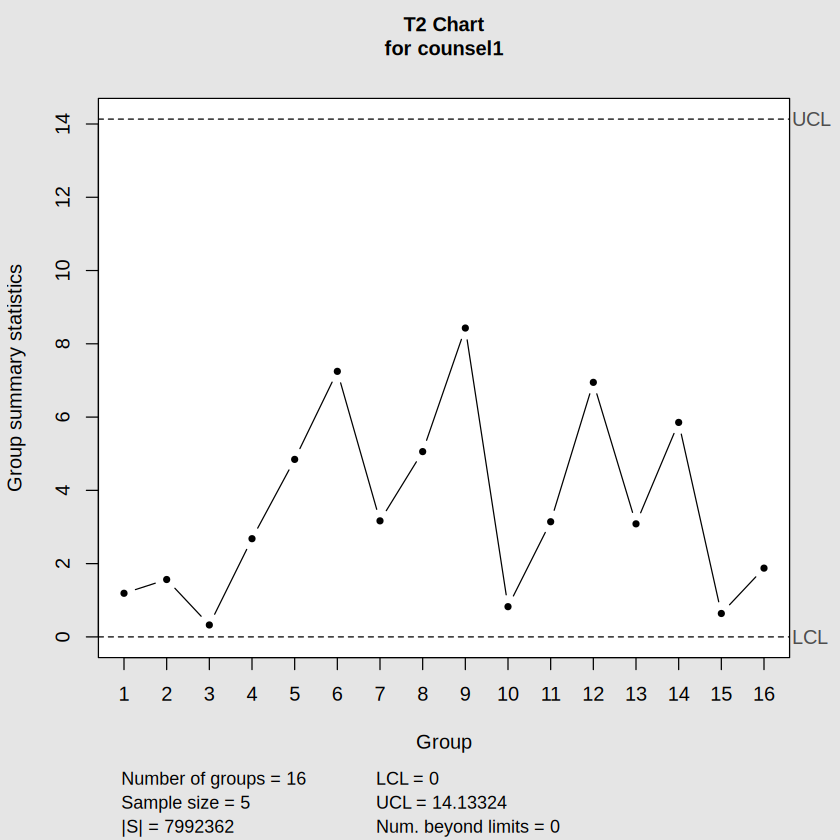

In [13]:
t2 <- mqcc(counsel1, type = "T2")

### Q5: Report the sample mean vector and sample variance-covariance matrix from Q4.

In [14]:
t2$center

Counselor1 Counselor2 Counselor3 Counselor4 
  45.34275   46.00288   45.28650   45.45975

In [15]:
t2$cov

,Counselor1,Counselor2,Counselor3,Counselor4
Counselor1,64.94685,25.20394,18.73784,28.36822
Counselor2,25.20394,63.96758,30.76070,26.36930
Counselor3,18.73784,30.76070,67.29034,14.95226
Counselor4,28.36822,26.36930,14.95226,60.67095


### Q6: Read the Phase II data (`Counselling_PhaseII.xlsx`) into R the same way. Using the mean vector and covariance matrix from Q5, construct a Phase II Hotelling's $T^2$ chart. Do we still have evidence of statistical control? If not, generate individual univariate Shewhart $\bar{X}$ and $s$ charts (using the appropriate mean and standard deviation from Phase I) to determine which counselor(s) may have out-of-control scores.

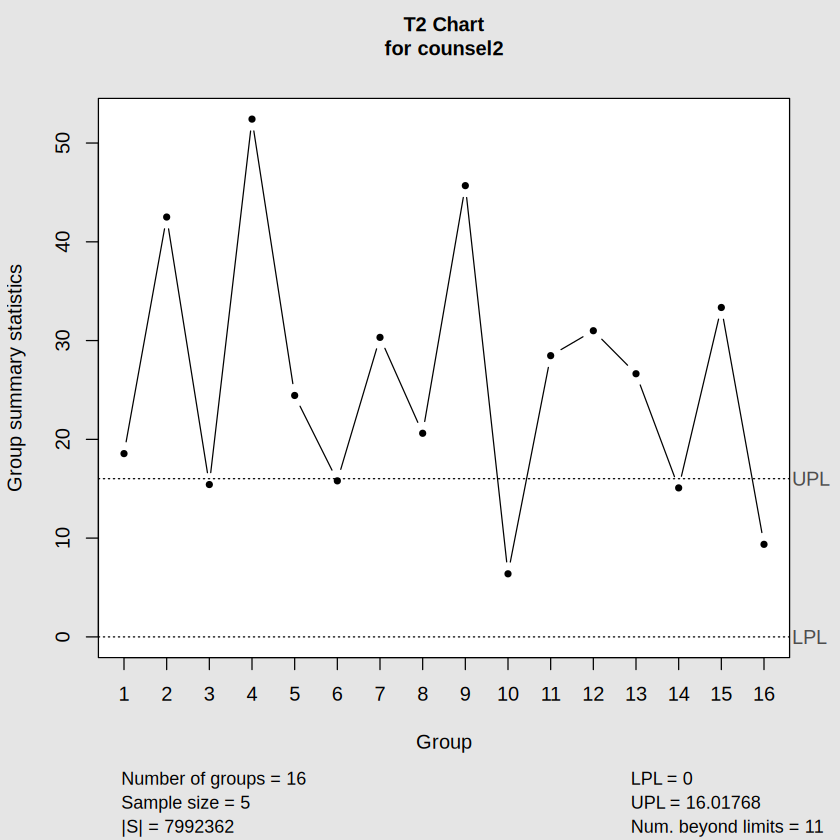

In [37]:
p2 <- mqcc(counsel2, type = "T2",
          center=t2$center,
          cov=t2$cov,
          limits=FALSE,pred.limits=TRUE,
          plot=T)

In [38]:
lapply(counsel2,FUN=function(x){

  return(mean(rowMeans(x)))

})

$Counselor1
[1] 46.16112

$Counselor2
[1] 44.43162

$Counselor3
[1] 59.6185

$Counselor4
[1] 44.552

In [41]:
c4 <- 0.94
n <- 5

counselor1_xbar <- t2$center[1]
counselor2_xbar <- t2$center[2]
counselor3_xbar <- t2$center[3]
counselor4_xbar <- t2$center[4]

counselor1_sd <- sqrt(t2$cov[1,1])/c4
counselor2_sd <- sqrt(t2$cov[2,2])/c4
counselor3_sd <- sqrt(t2$cov[3,3])/c4
counselor4_sd <- sqrt(t2$cov[4,4])/c4

In [42]:
counselor1_sd
counselor1_xbar
counselor3_xbar

[1] 8.573362

Counselor1 
  45.34275

Counselor3 
   45.2865

In [45]:
counselor1_ucl <- counselor1_xbar + 3*counselor1_sd/sqrt(n)
counselor1_lcl <- counselor1_xbar - 3*counselor1_sd/sqrt(n)

counselor2_ucl <- counselor2_xbar + 3*counselor2_sd/sqrt(n)
counselor2_lcl <- counselor2_xbar - 3*counselor2_sd/sqrt(n)

counselor3_ucl <- counselor3_xbar + 3*counselor3_sd/sqrt(n)
counselor3_lcl <- counselor3_xbar - 3*counselor3_sd/sqrt(n)

counselor4_ucl <- counselor4_xbar + 3*counselor4_sd/sqrt(n)
counselor4_lcl <- counselor4_xbar - 3*counselor4_sd/sqrt(n)

Warning message in qcc(rowMeans(counsel2$Counselor1), type = "xbar", center = counselor1_xbar, :
“'std.dev' is not used when limits is given”


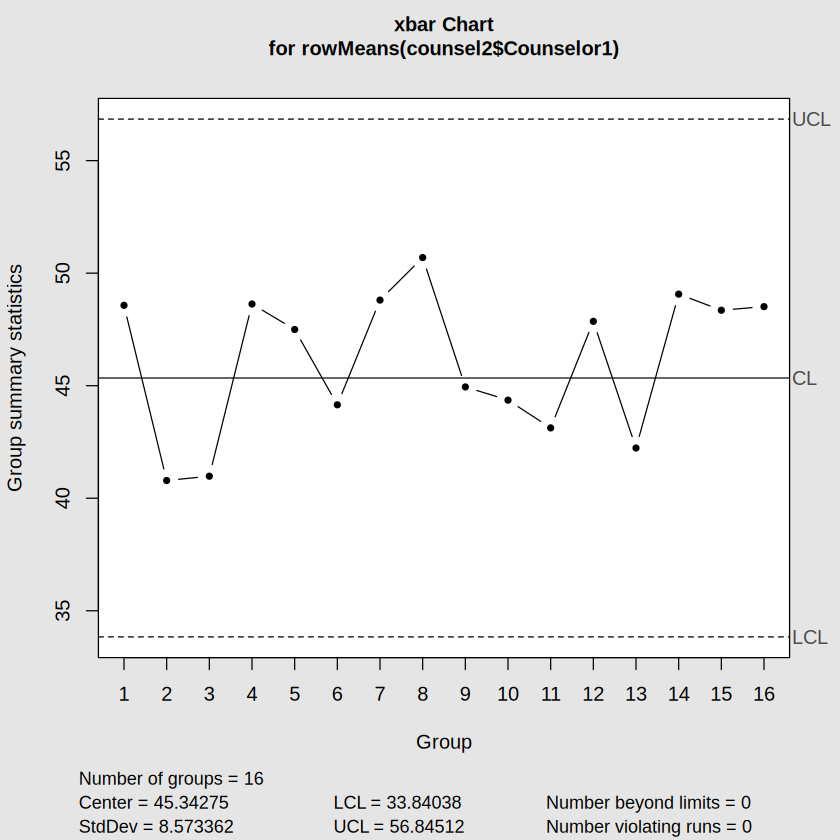

In [52]:
xbar1 <- qcc(rowMeans(counsel2$Counselor1),
             type="xbar",
             center=counselor1_xbar,
             std.dev=counselor1_sd,
             sizes=5,
             limits=c(counselor1_lcl,counselor1_ucl))

Warning message in qcc(rowMeans(counsel2$Counselor2), type = "xbar", center = counselor2_xbar, :
“'std.dev' is not used when limits is given”


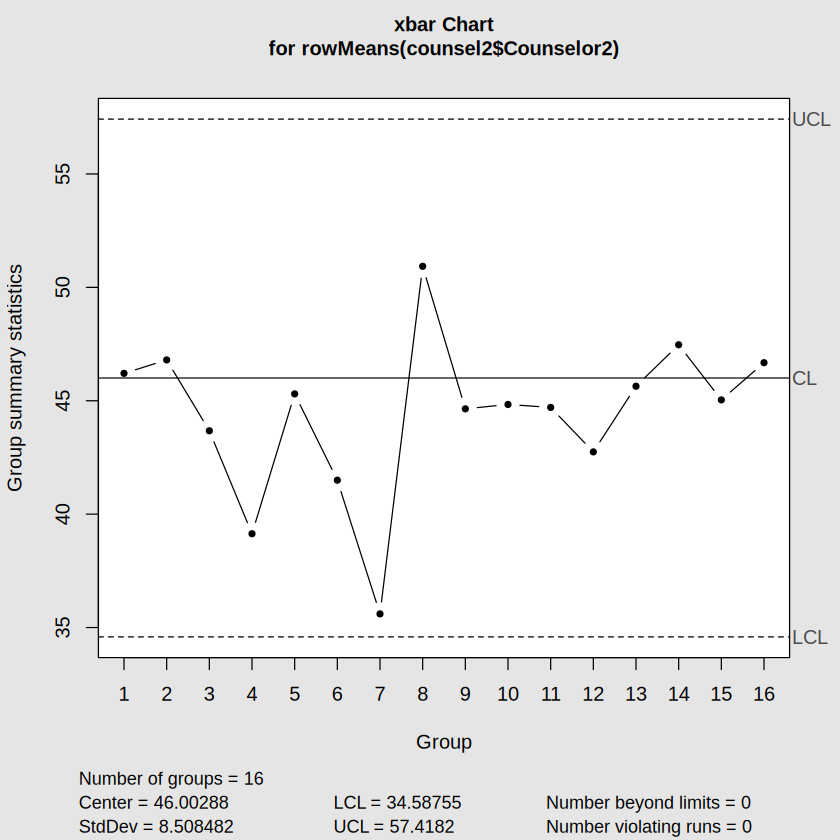

In [47]:
xbar2 <- qcc(rowMeans(counsel2$Counselor2),
             type="xbar",
             center=counselor2_xbar,
             std.dev=counselor2_sd,
             sizes=5,
             limits=c(counselor2_lcl,counselor2_ucl))

Warning message in qcc(rowMeans(counsel2$Counselor3), type = "xbar", center = counselor3_xbar, :
“'std.dev' is not used when limits is given”


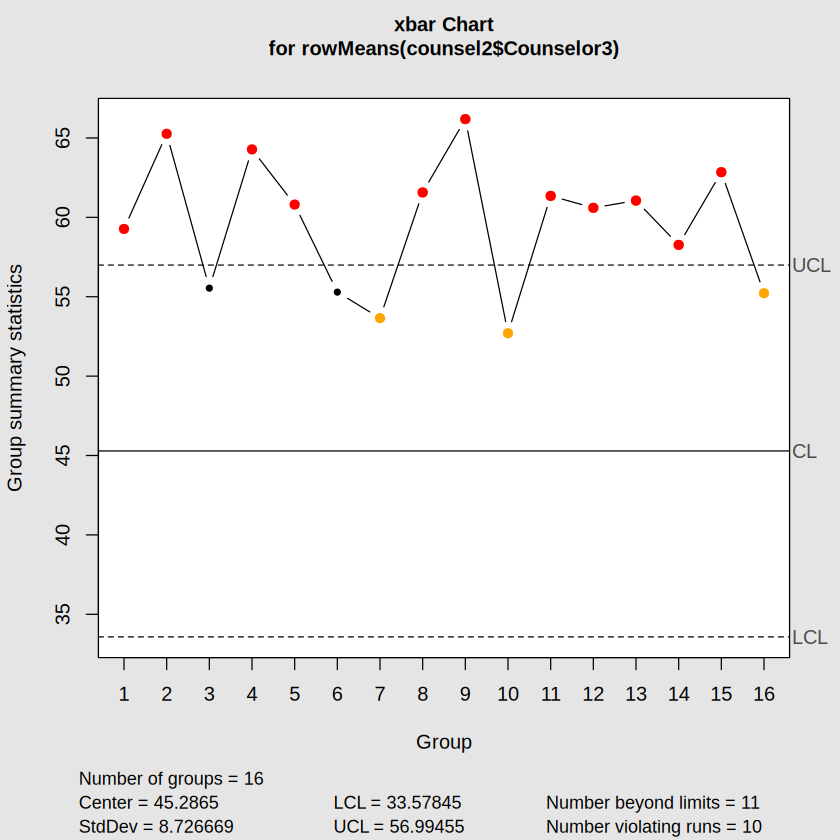

In [48]:
xbar3 <- qcc(rowMeans(counsel2$Counselor3),
             type="xbar",
             center=counselor3_xbar,
             std.dev=counselor3_sd,
             sizes=5,
             limits=c(counselor3_lcl,counselor3_ucl))

Warning message in qcc(rowMeans(counsel2$Counselor4), type = "xbar", center = counselor4_xbar, :
“'std.dev' is not used when limits is given”


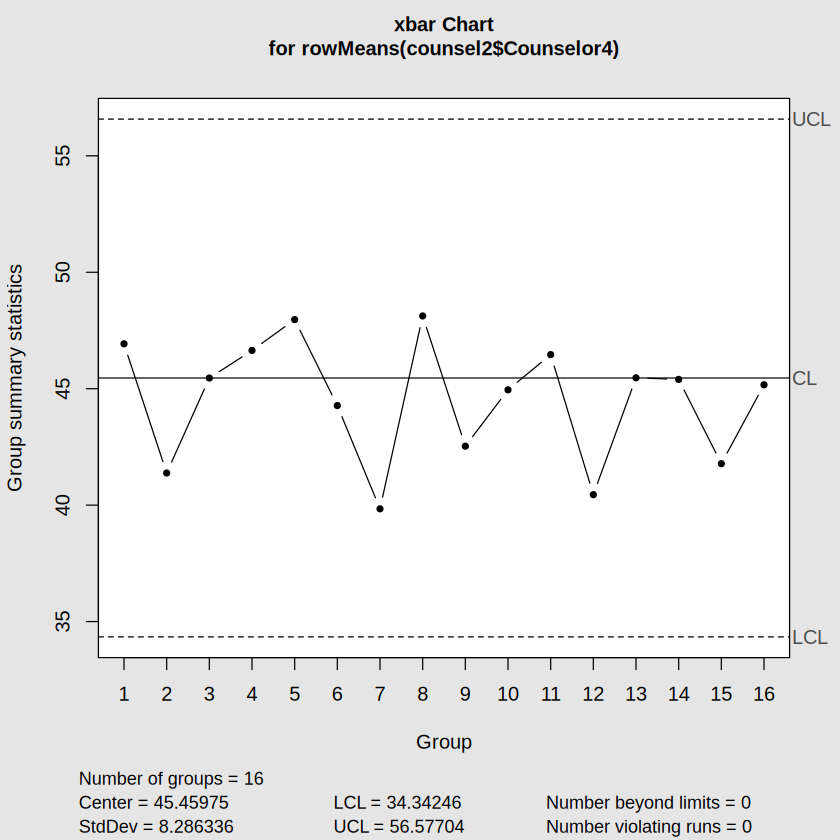

In [49]:
xbar4 <- qcc(rowMeans(counsel2$Counselor4),
             type="xbar",
             center=counselor4_xbar,
             std.dev=counselor4_sd,
             sizes=5,
             limits=c(counselor4_lcl,counselor4_ucl))

In [53]:
## s chart constants for n = 5 ##
B5 <- 0
B6 <- 1.964

counselor1_s_center <- c4*counselor1_sd
counselor2_s_center <- c4*counselor2_sd
counselor3_s_center <- c4*counselor3_sd
counselor4_s_center <- c4*counselor4_sd

counselor1_s_ucl <- B6*counselor1_sd
counselor1_s_lcl <- B5*counselor1_sd

counselor2_s_ucl <- B6*counselor2_sd
counselor2_s_lcl <- B5*counselor2_sd

counselor3_s_ucl <- B6*counselor3_sd
counselor3_s_lcl <- B5*counselor3_sd

counselor4_s_ucl <- B6*counselor4_sd
counselor4_s_lcl <- B5*counselor4_sd

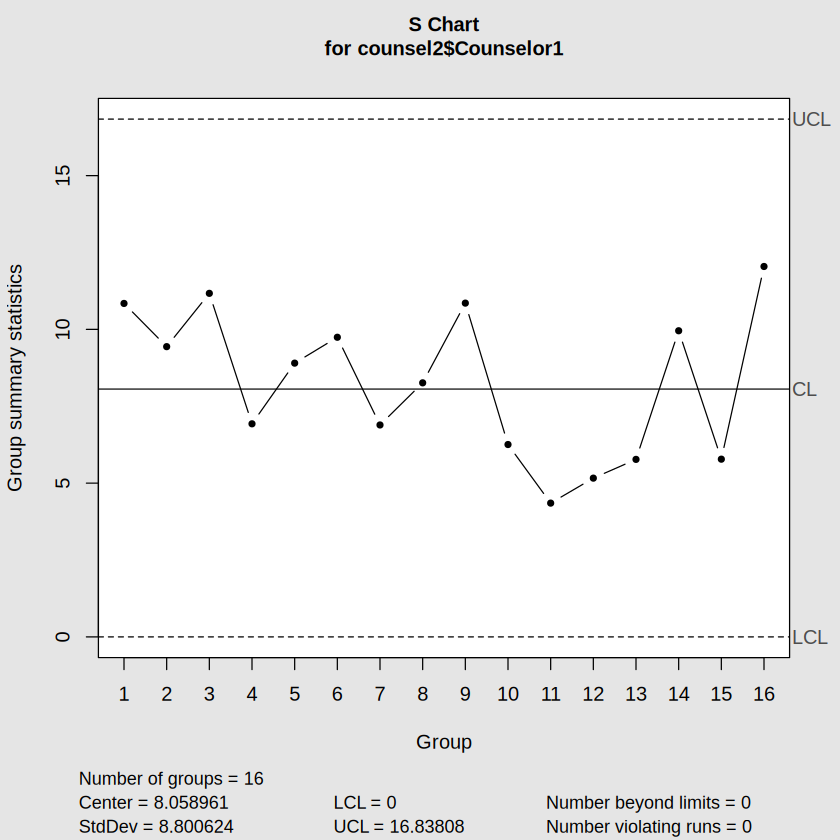

In [54]:
s1 <- qcc(counsel2$Counselor1,
          type="S",
          center=counselor1_s_center,
          limits=c(counselor1_s_lcl,counselor1_s_ucl))

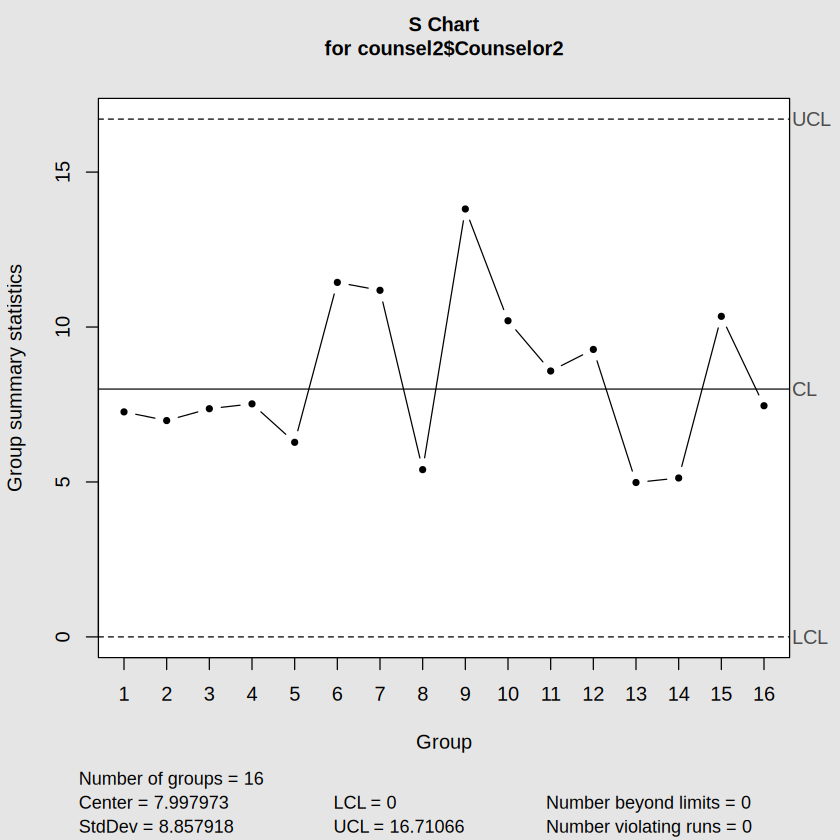

In [55]:
s2 <- qcc(counsel2$Counselor2,
          type="S",
          center=counselor2_s_center,
          limits=c(counselor2_s_lcl,counselor2_s_ucl))

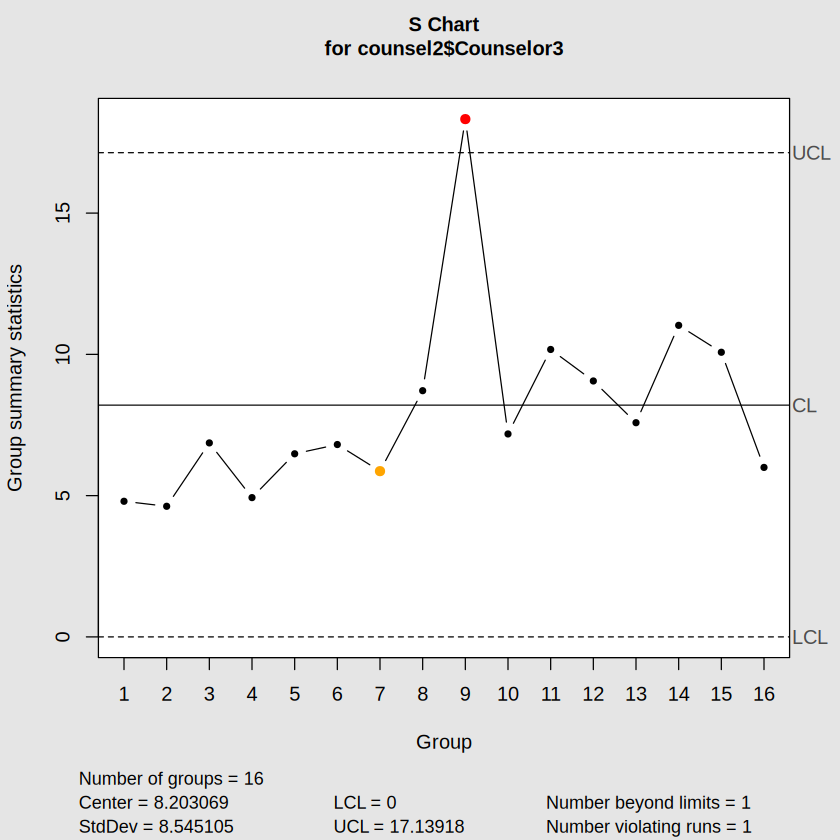

In [56]:
s3 <- qcc(counsel2$Counselor3,
          type="S",
          center=counselor3_s_center,
          limits=c(counselor3_s_lcl,counselor3_s_ucl))

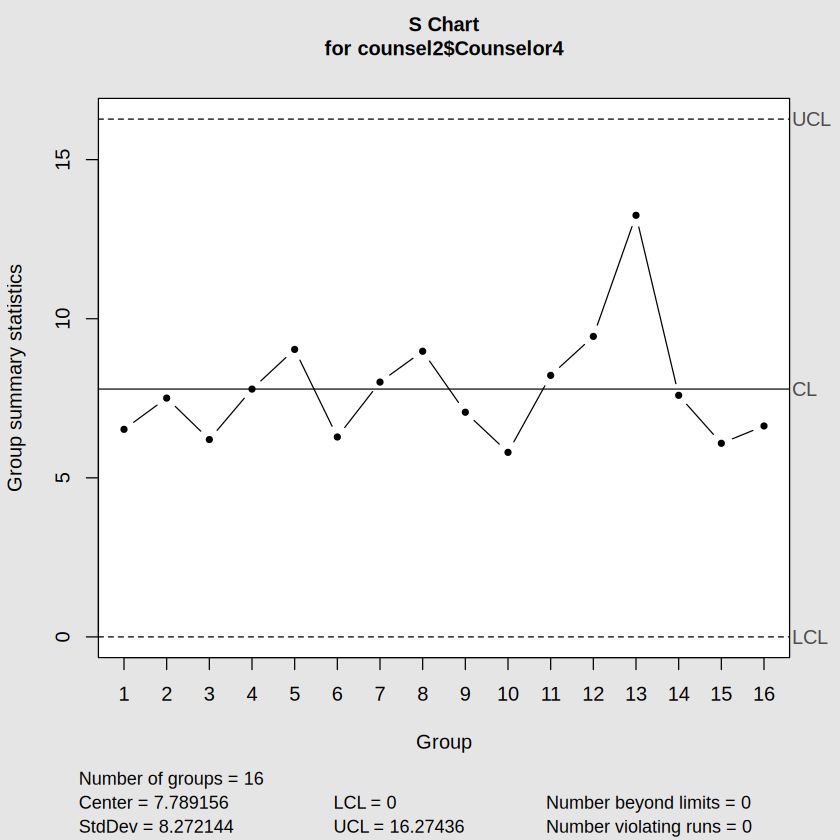

In [57]:
s4 <- qcc(counsel2$Counselor4,
          type="S",
          center=counselor4_s_center,
          limits=c(counselor4_s_lcl,counselor4_s_ucl))

### Q7: What is the benefit of using a multivariate control chart over several separate univariate control charts? What is one limitation?

## Improve

### Q8: Based on your findings in Q6, briefly describe what intervention(s) you, as the director, might reasonably take regarding the counselor(s) flagged as out of control.

## Control

### Q9: It is reasonable to assume that this same monitoring situation could also be conceptualized as a **multiple stream process (MSP)** -- that is, treating the four counselors as independent, parallel processes rather than a single correlated multivariate one. Perform the same Phase I analysis as before, but using the Control Chart for Each Stream MSP technique ($L = 3.46$). Do we have evidence of statistical control?

In [61]:
## Q9 Code ##
stream_summary <- function(dat_list) {
  lapply(names(dat_list), FUN = function(nm) {
    x <- dat_list[[nm]]
    tibble(Week      = seq_len(nrow(x)),
           Means     = rowMeans(x),
           Ranges    = apply(x, 1, FUN = function(r) max(r) - min(r)),
           Counselor = nm)
  }) |> setNames(names(dat_list))
}

samp_list <- stream_summary(counsel1)

n  <- 5
d2 <- 2.326
L  <- 3.46

In [62]:
stream_plot <- function(df, center, lcl, ucl, phase) {
  df |>
    ggplot(aes(x = Week, y = Means)) +
    geom_point(color = "red") + geom_line(color = "red") +
    geom_hline(yintercept = ucl, color = "black") +
    geom_hline(yintercept = lcl, color = "black") +
    geom_hline(yintercept = center, color = "black", linetype = "dashed") +
    labs(x = "Week", y = "Mean Depressive-Symptom Score",
         title = paste(phase, "Chart for", unique(df$Counselor))) +
    theme_classic() +
    theme(plot.title = element_text(hjust = 0.5)) +
    scale_x_continuous(breaks = 1:16)
}

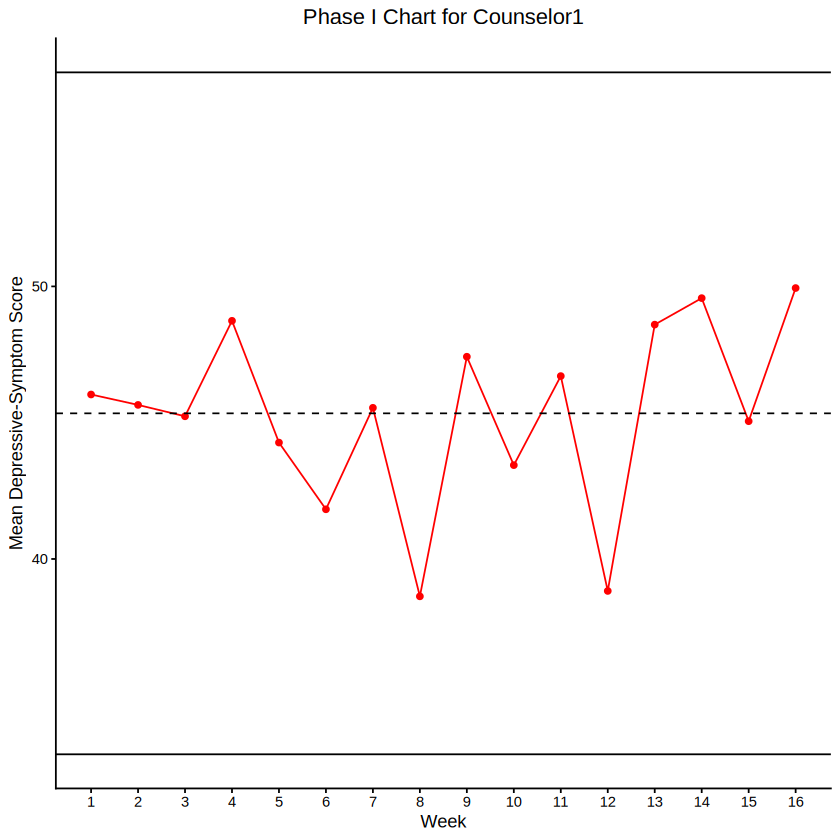

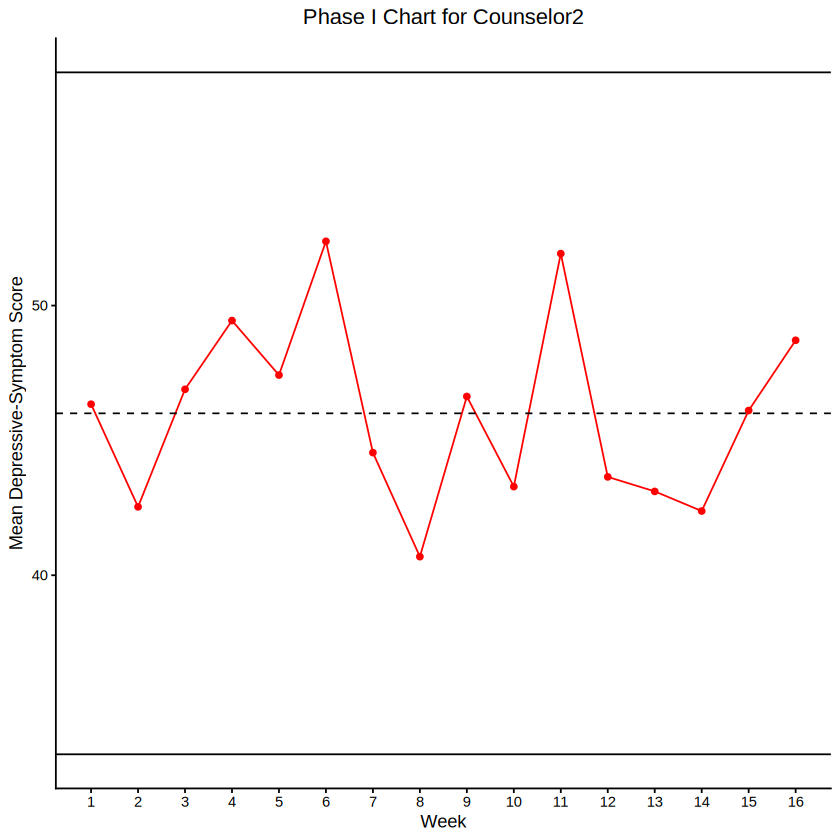

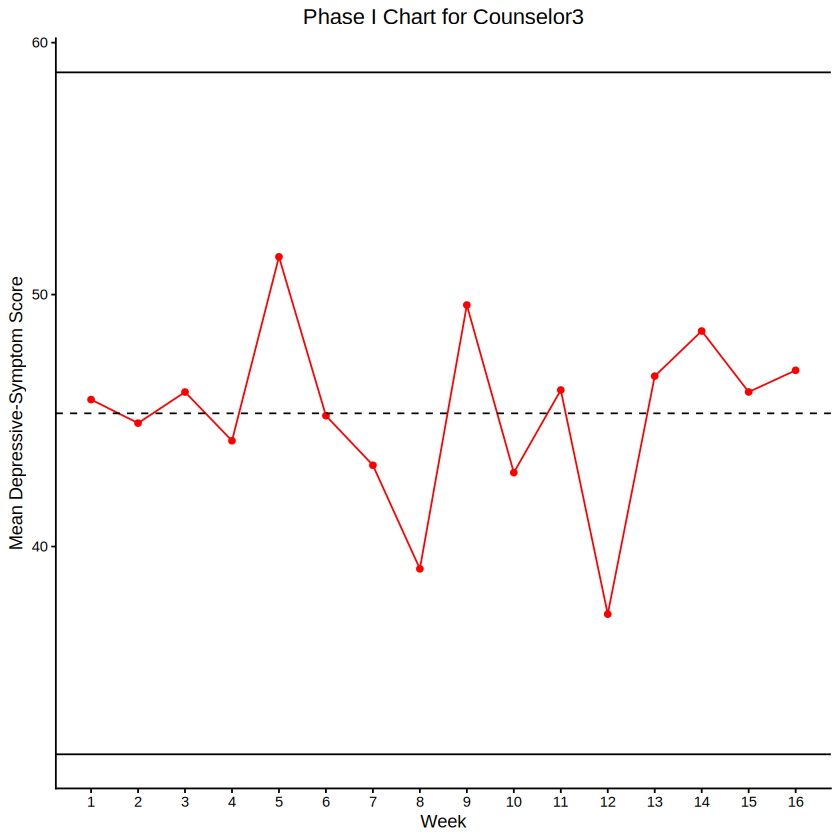

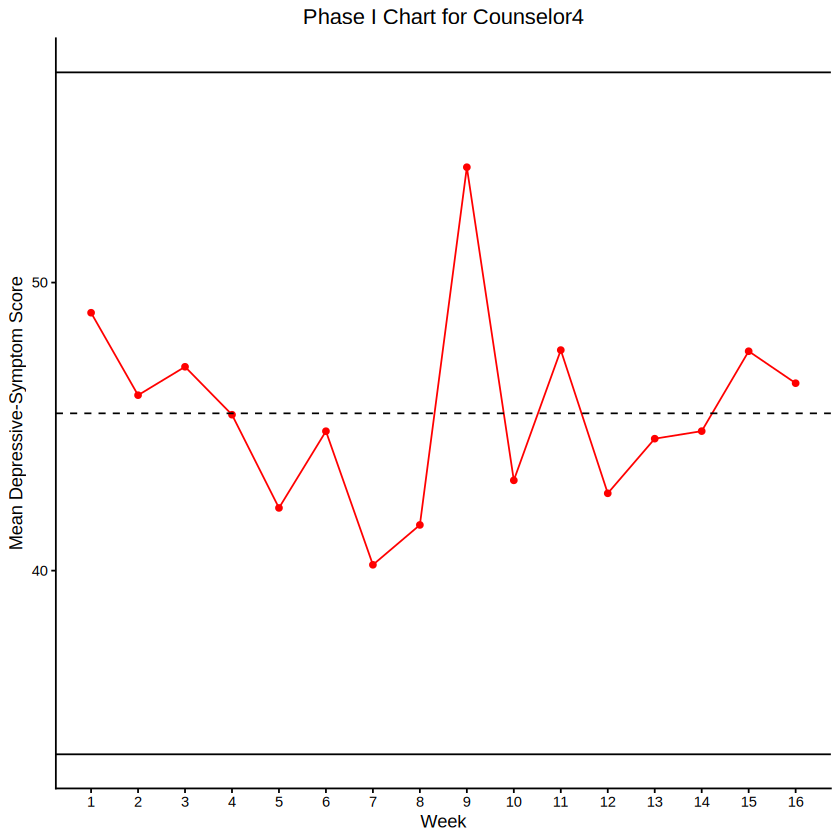

In [63]:
cfes <- lapply(samp_list, FUN = function(x) {

  xdbar <- mean(x$Means)
  rbar  <- mean(x$Ranges)

  UCL <- xdbar + L * rbar / (d2 * sqrt(n))
  LCL <- xdbar - L * rbar / (d2 * sqrt(n))

  print(stream_plot(x, xdbar, LCL, UCL, "Phase I"))

  list(Center     = xdbar,
       Limits     = c(LCL = LCL, UCL = UCL),
       Violations = x |> filter(Means > UCL | Means < LCL) |> pull(Week))
})

### Q10: Perform Phase II analysis using the Control Chart for Each Stream MSP technique. Do we still have evidence of statistical control? If not, which stream(s) (i.e., counselors) may be causing the out-of-control point(s)?

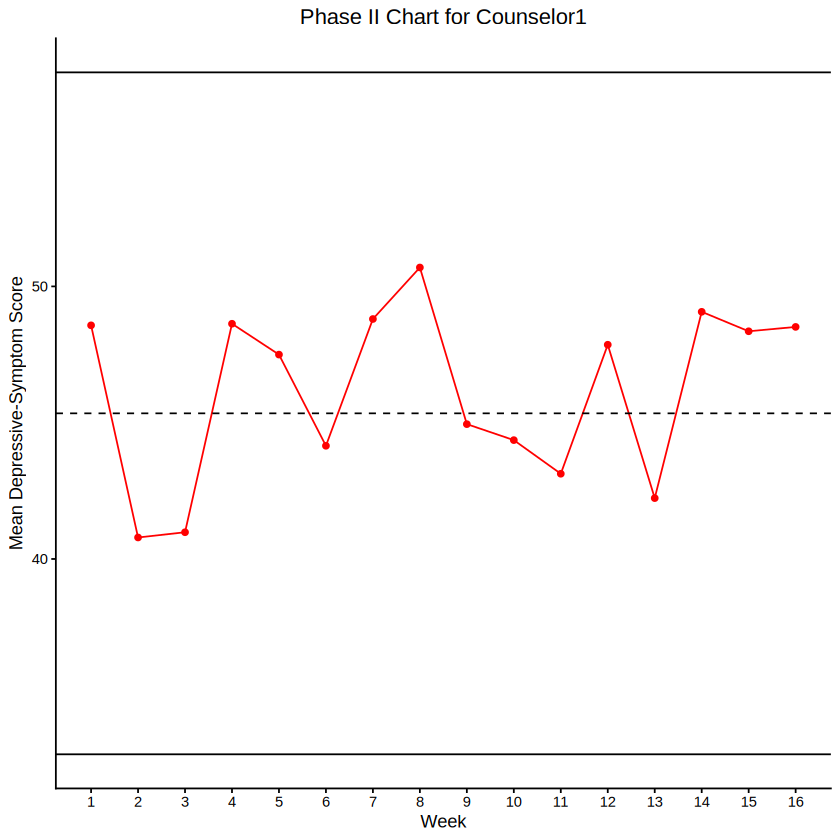

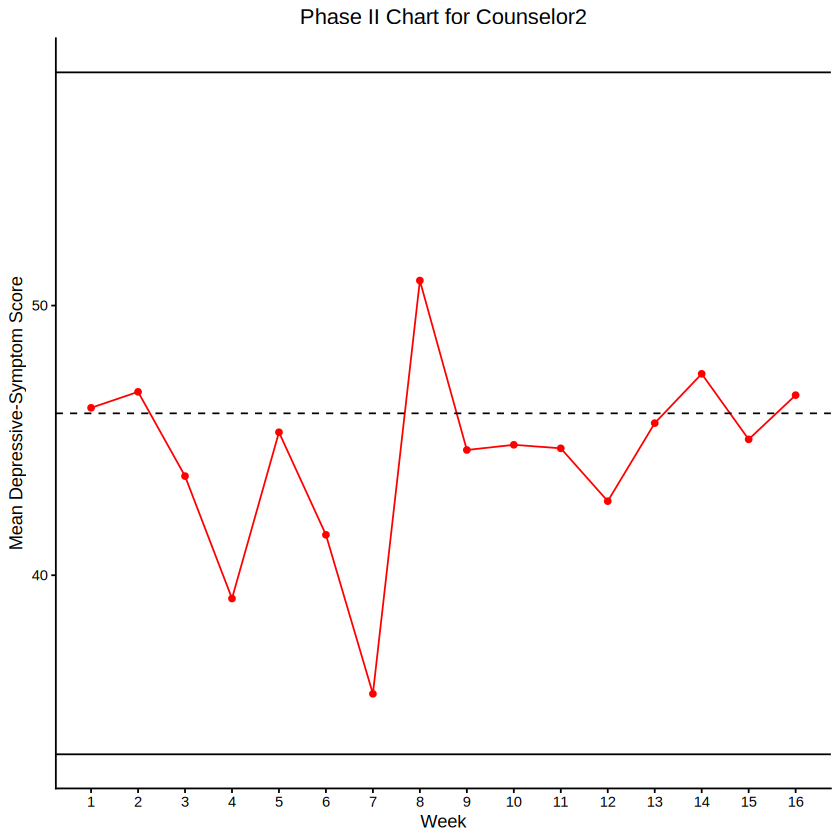

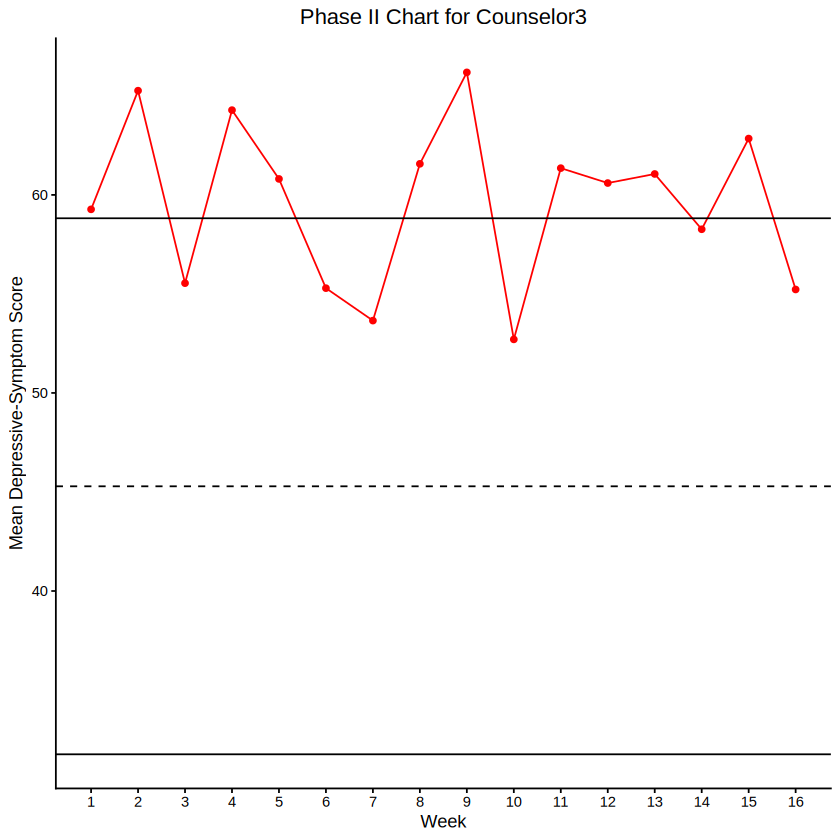

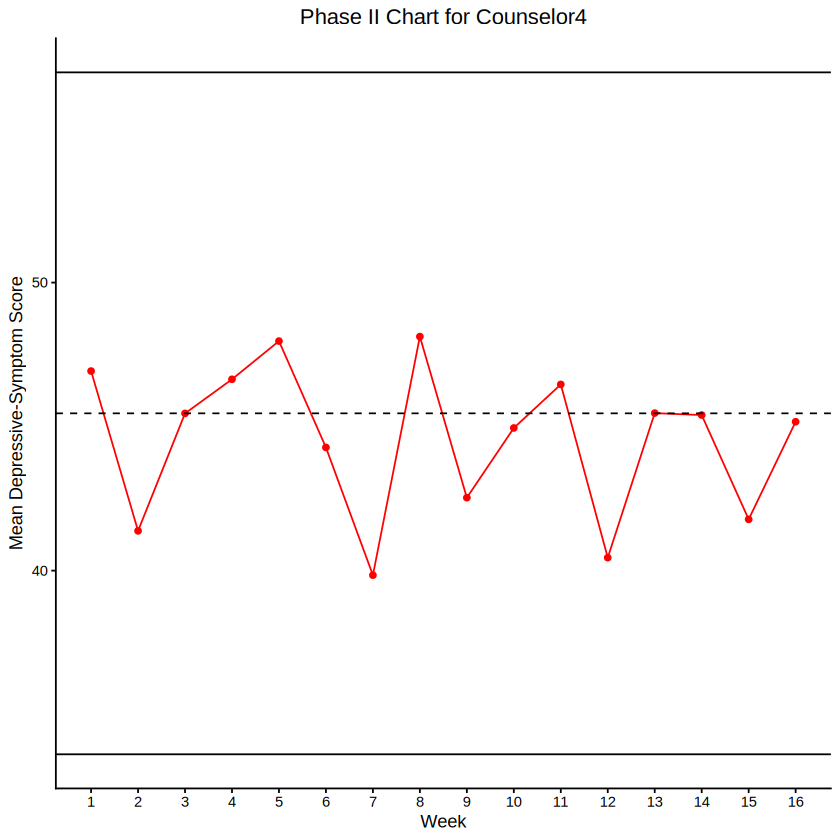

In [64]:
samp_list2 <- stream_summary(counsel2)

## Plot each stream against its *Phase I* limits and record violations ##
cfes2 <- lapply(names(samp_list2), FUN = function(nm) {

  df     <- samp_list2[[nm]]
  limits <- cfes[[nm]]$Limits
  center <- cfes[[nm]]$Center

  print(stream_plot(df, center, limits["LCL"], limits["UCL"], "Phase II"))

  df |> filter(Means > limits["UCL"] | Means < limits["LCL"]) |> pull(Week)
}) |> setNames(names(samp_list2))

### Q11: What is a difference between a multivariate process and a multiple stream process? Given what you found in Q4-Q10, which framing do you think is the more defensible choice for this specific scenario, and why?

### Q12: Provide an overview of your results that you, as the director, could bring to the university's Vice President of Student Affairs. What is the current status of The Owl's Nest program, and what actions (if any) have you taken or would you recommend?